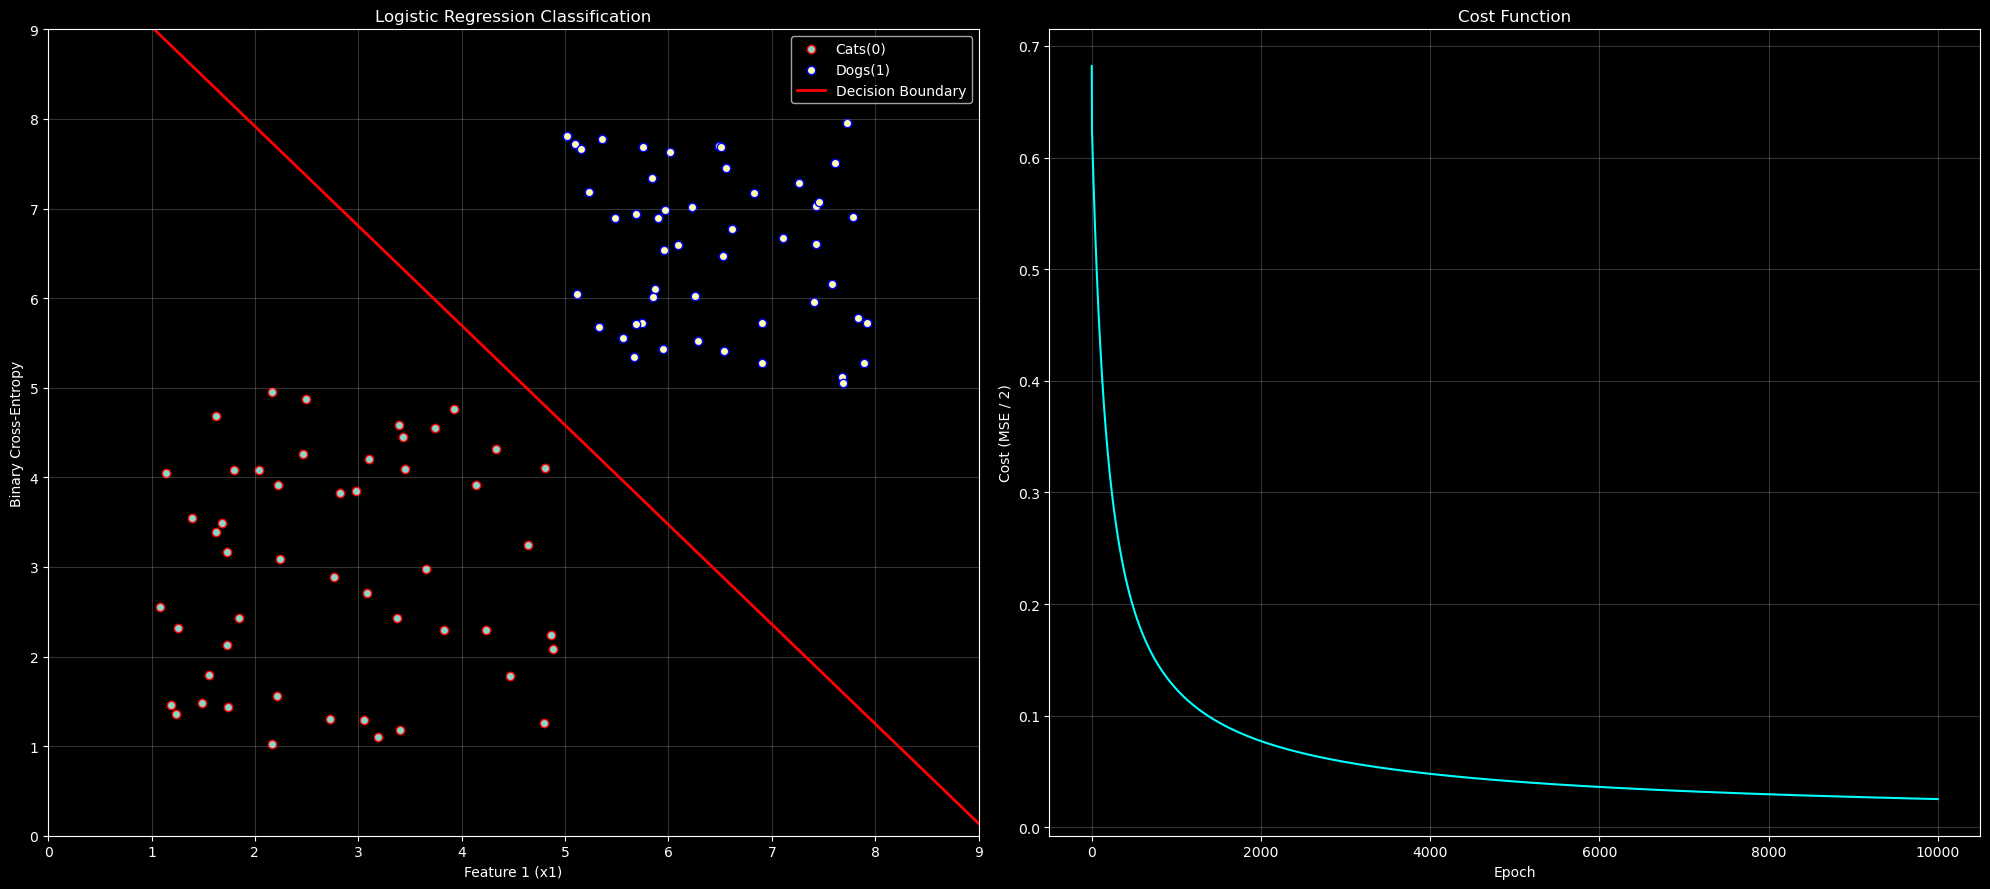

In [2]:
import numpy as np
import matplotlib.pyplot as plt 

plt.style.use("dark_background")
np.random.seed(42)
n_samples = 50 
cats_x1 =np.random.uniform(1,5,n_samples)
cats_x2 = np.random.uniform(1,5,n_samples)
cats_label = np.zeros(n_samples)
cats=np.column_stack([cats_x1,cats_x2])


dogs_x1 =np.random.uniform(5,8,n_samples)
dogs_x2 = np.random.uniform(5,8,n_samples)
dogs_label = np.ones(n_samples)
dogs=np.column_stack([dogs_x1,dogs_x2])

x = np.vstack([cats,dogs])
y = np.concatenate([cats_label,dogs_label])


plt.figure(figsize=(20,9),dpi=100)
plt.subplot(1,2,1)
plt.scatter(cats[:,0],cats[:,1],marker="o",label="Cats(0)",edgecolors="r")
plt.scatter(dogs[:,0],dogs[:,1],marker="o",label="Dogs(1)",edgecolors="b")

indicies = np.random.permutation(len(x))
x = x[indicies]
y = y[indicies]

x_bias = np.column_stack([np.ones(len(x)),x]) # ones عشان نضيف عمود 
w = np.random.rand(3) * 0.01 # عشان عايز اقلل الويت شوية 

eta = 0.1
epochs = 10000
costVal = np.zeros(epochs)

for i in range(epochs):
    z = x_bias @ w
    h = 1 / (1+np.exp(-z)) # بتحول الناتج الي احتمال بين 0 و 1 
    error = h - y
    w = w - eta * (x_bias.T @ error) / len(x)
    costVal[i] =-np.mean(y * np.log(h+1e-10)+ (1-y) * np.log(1-h+1e-10) )

    if costVal[i] <1e-5 :
        break

b= w[0]        
w1= w[1]        
w2= w[2]      



# Decision boundary: w1*x1 + w2*x2 + b = 0
x1_vals = np.linspace(0, 9, 100)
x2_vals = -(w1 * x1_vals + b) / w2

plt.plot(x1_vals, x2_vals, "-r",
         linewidth=2, label="Decision Boundary")

plt.xlabel("Feature 1 (x1)")
plt.ylabel("Feature 2 (x2)")
plt.xlim(0, 9)
plt.ylim(0, 9)
plt.title("Logistic Regression Classification")
plt.ylabel("Binary Cross-Entropy")
plt.legend()
plt.grid(alpha=0.2)

# Plot 2: Cost function
plt.subplot(1, 2, 2)

plt.plot(range(1, i + 2), costVal[:i + 1], color="cyan")

plt.xlabel("Epoch")
plt.ylabel("Cost (MSE / 2)")
plt.title("Cost Function")
plt.grid(True,alpha=0.2)

plt.tight_layout()
plt.show()
    